
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining S&P 500 Sectors.  Construct portfolios from the S&P 500 Sector ETFs and examine the results of different weighting schemes.  In particular, we can select the best performing sectors over a given period.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['etf-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='1 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,SPY,S&P 500 ETF,US Stocks:Large Cap,8.09,27.12,20.30,20.85,21.70,13.17,10.18,3.80,12.71,12.77,15.74,20.30,12.77,1.59
1,DIA,DJIA ETF,US Stocks:Large Cap,22.28,21.08,19.13,19.57,17.65,10.68,10.54,5.17,9.35,11.94,14.87,19.13,11.94,1.60
2,QQQ,Nasdaq 100 ETF,US Stocks:Growth,-10.95,39.83,25.53,26.54,25.46,14.96,17.90,7.06,21.18,17.49,20.91,25.53,17.49,1.46
3,VTI,Vanguard Total Stock Market Index ETF,US Stocks:Total Stock Market,8.77,26.91,20.33,21.06,21.49,12.27,10.77,4.19,12.53,13.15,15.98,20.33,13.15,1.55
4,IWM,Russell 2000 ETF,US Stocks:Small Cap,8.56,29.07,26.65,29.30,18.15,7.87,14.25,7.50,14.45,19.40,20.62,26.65,19.40,1.37
5,MDY,S&P 400 Midcap ETF,US Stocks:Mid Cap,7.03,13.01,16.92,19.05,14.67,8.51,12.93,7.04,11.24,15.45,18.03,16.92,15.45,1.10
6,IWD,Russell 1000 Value ETF,US Stocks:Value,40.65,33.05,30.29,30.39,20.24,12.04,7.81,4.24,10.09,12.32,14.89,30.29,12.32,2.46
7,IWF,Russell 1000 Growth ETF,US Stocks:Growth,-14.73,19.37,9.99,11.24,21.84,12.32,17.33,6.82,17.64,16.58,19.35,9.99,16.58,0.60
8,RSP,S&P 500 Equal Weight ETF,US Stocks:Growth,26.67,17.83,18.80,19.64,16.16,9.35,9.71,4.39,9.72,12.74,15.79,18.80,12.74,1.48
9,SPSM,S&P 600 Small Cap ETF,US Stocks:Small Cap,23.09,27.17,24.30,26.29,15.59,7.79,12.71,6.81,13.51,18.85,20.03,24.30,18.85,1.29


In [6]:
# Sector Ranking
sector_rank = bb.rank(df, rank_by='Sharpe Ratio')
sector_rank = sector_rank[sector_rank['Description'].str.contains('Sector ETF')]
#sector_rank = sector_rank.loc[(sector_rank['3 mo'] > 0) & sector_rank['1 Yr'] > 0]
#sector_rank = rank_filtered.head(10)
sector_rank

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
16,XLE,S&P500 Energy Sector ETF,US Stocks:Energy,58.22,29.13,44.88,45.60,16.47,26.79,23.02,9.90,22.78,19.84,25.80,44.88,19.84,2.26
23,XLV,S&P500 Healthcare Sector ETF,US Stocks:Healthcare,75.00,16.11,27.14,27.38,10.44,6.40,18.32,7.76,14.64,14.11,14.91,27.14,14.11,1.92
19,XLK,S&P500 Technology Sector ETF,US Stocks:Technology,-10.28,79.95,41.17,44.17,30.37,19.88,26.57,11.11,30.18,22.94,24.00,41.17,22.94,1.79
14,XLB,S&P500 Materials Sector ETF,US Stocks:Materials,18.60,0.77,17.52,17.93,11.68,6.99,15.28,6.21,15.64,15.74,19.36,17.52,15.74,1.11
18,XLI,S&P500 Industrials Sector ETF,US Stocks:Industrials,10.67,1.06,17.16,18.24,20.03,13.23,14.05,7.48,16.49,16.06,18.41,17.16,16.06,1.07
20,XLP,S&P500 Consumer Staples Sector ETF,US Stocks:Consumer Staples,15.99,-7.59,8.73,8.58,8.49,6.03,14.13,8.49,15.11,11.78,13.42,8.73,11.78,0.74
17,XLF,S&P500 Financials Sector ETF,US Stocks:Financials,63.25,29.84,9.71,9.52,21.52,10.95,9.75,5.11,11.78,14.12,17.59,9.71,14.12,0.69
21,XLRE,S&P500 Real Estate Sector ETF,US Stocks:Real Estate,8.24,6.17,9.06,9.97,10.50,2.27,11.00,6.67,13.23,16.46,19.15,9.06,16.46,0.55
15,XLC,S&P500 Communication Services Sector ETF,US Stocks:Communication Services,-8.06,-7.32,2.90,1.63,20.62,7.53,17.45,8.11,14.01,13.72,18.61,2.90,13.72,0.21
22,XLU,S&P500 Utilities Sector ETF,US Stocks:Utilities,-12.16,-17.69,3.01,4.11,13.77,7.27,13.06,9.17,14.97,14.73,16.53,3.01,14.73,0.20


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# S&P 500 Sectors - top 4
top_sectors_portfolio = {
    'Title': 'Top S&P500 Sectors Portfolio'
}
top_sectors = list(sector_rank['Investment Option'])[:4]
top_sectors_portfolio.update(dict.fromkeys(top_sectors, 1/len(top_sectors)))

# S&P 500 Sectors - all
all_sectors_portfolio = {
    'Title': 'All S&P500 Sectors Portfolio'
}
all_sectors = list(sector_rank['Investment Option'])
all_sectors_portfolio.update(dict.fromkeys(all_sectors, 1/len(all_sectors)))

### Custom Portfolios

In [8]:
# my portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = all_sectors_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,XLE,XLV,XLK,XLB,XLI,XLP,XLF,XLRE,XLC,XLU,XLY,All S&P500 Sectors Portfolio
Annual Returns,44.88,27.14,41.17,17.52,17.16,8.73,9.71,9.06,2.90,3.01,1.07,16.35
Std Dev,19.84,14.11,22.94,15.74,16.06,11.78,14.12,16.46,13.72,14.73,17.49,9.01
Sharpe Ratio,2.26,1.92,1.79,1.11,1.07,0.74,0.69,0.55,0.21,0.20,0.06,1.82
Weight,0.09,0.09,0.08,0.09,0.09,0.09,0.09,0.09,0.09,0.09,0.09,1.00
Worst Typical Down Year,5.20,-1.08,-4.71,-13.96,-14.96,-14.83,-18.53,-23.86,-24.54,-26.45,-33.91,-1.66
Black Swan,-14.64,-15.19,-27.65,-29.70,-31.02,-26.61,-32.65,-40.32,-38.26,-41.18,-51.40,-10.67


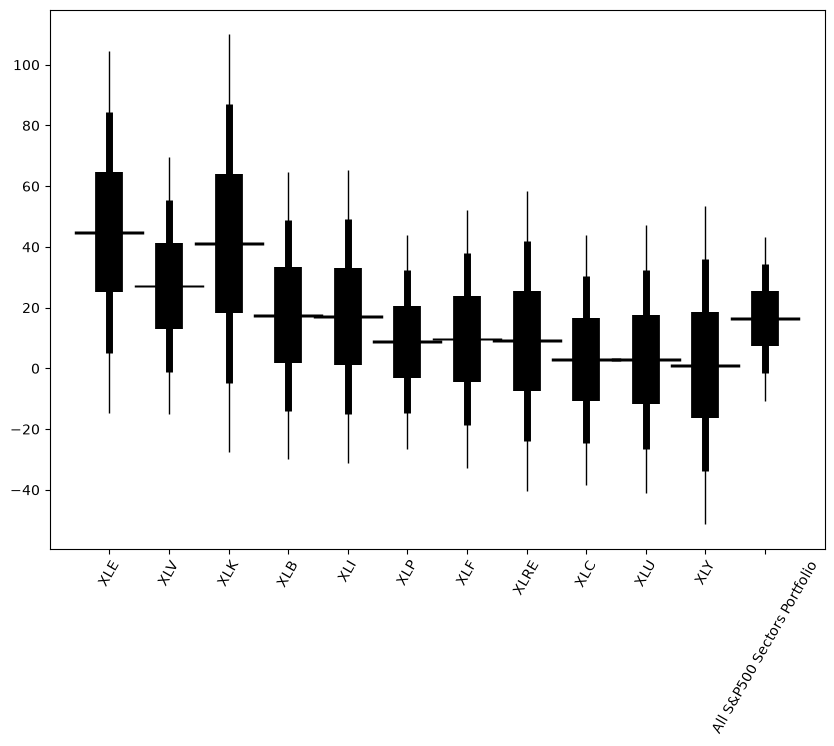

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

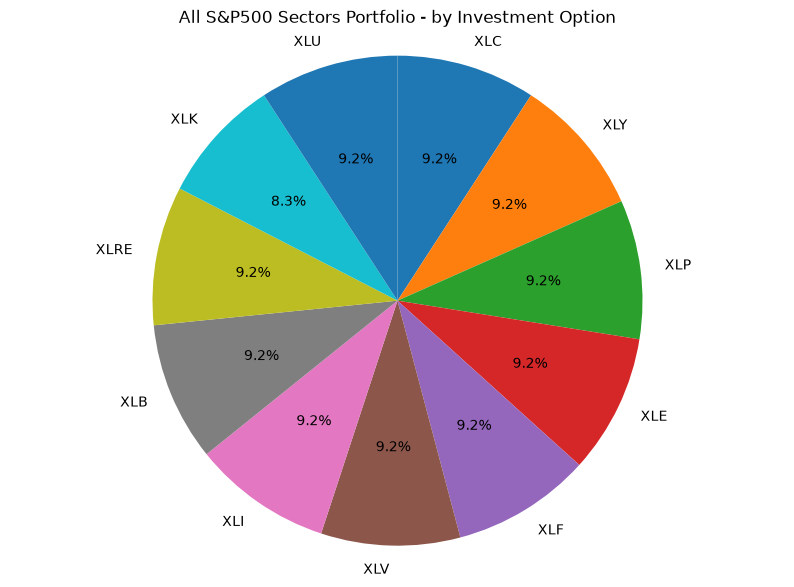

XLC    0.09
XLY    0.09
XLP    0.09
XLE    0.09
XLF    0.09
XLV    0.09
XLI    0.09
XLB    0.09
XLRE   0.09
XLK    0.08
XLU    0.09



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

All S&P500 Sectors Portfolio Weights:
    XLE                            0.0917
    XLV                            0.0917
    XLK                            0.0826
    XLB                            0.0917
    XLI                            0.0917
    XLP                            0.0917
    XLF                            0.0917
    XLRE                           0.0917
    XLC                            0.0917
    XLU                            0.0917
    XLY                            0.0917


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).